# Лабораторная работа №3
## Классификация и оценка качества моделей

**Курс:** Основы машинного обучения  
**Цель:** Реализовать ключевые метрики классификации вручную и применить несколько алгоритмов на реальных данных с дисбалансом классов.  
**Тема:** Классификация и оценка качества моделей  
**Дедлайн:** см. таблицу учёта успеваемости

---

### Инструкция по выполнению

1. **Вариант:** укажите свой `Student_ID` в задании 0.1 — он определит датасет и параметры задания
2. **Именование переменных:** строго соблюдайте указанные имена — они используются для автопроверки
3. **Функции:** реализуйте каждую функцию с указанной сигнатурой; не меняйте имена функций и параметров
4. **Визуализации:** все графики должны иметь заголовок и подписи осей
5. **Сохранение:** перед сдачей выполните `Kernel → Restart & Run All` и убедитесь, что ошибок нет

---
## Блок 0: Настройка варианта

### Задание 0.1: Укажите свой Student_ID

Найдите свой порядковый номер (поле «№ п/п») в таблице учёта успеваемости курса и укажите его ниже.

In [1]:
Student_ID = 14  # Укажите свой порядковый номер, например: Student_ID = 7

### Задание 0.2: Определение варианта

Выполните ячейку ниже — она определит ваш датасет и параметры задания.

In [2]:
# (dataset_name, uci_id, target_col, description)
# dataset_name — короткое название датасета
# uci_id       — идентификатор датасета в репозитории UCI ML Repository
# target_col   — название целевой переменной
# description  — полное название датасета и источник для загрузки
datasets = [
    (
        'bank_marketing',
        222,
        'y',
        'Bank Marketing (UCI id=222): подписка клиента на срочный вклад, '
        'https://archive.ics.uci.edu/dataset/222/bank+marketing'
    ),
    (
        'credit_default',
        350,
        'default payment next month',
        'Default of Credit Card Clients (UCI id=350): дефолт по кредитной карте, '
        'https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients'
    ),
    (
        'htru2',
        372,
        'class',
        'HTRU2 (UCI id=372): классификация кандидатов в пульсары, '
        'https://archive.ics.uci.edu/dataset/372/htru2'
    ),
    (
        'adult',
        2,
        'income',
        'Adult / Census Income (UCI id=2): доход физического лица выше $50K, '
        'https://archive.ics.uci.edu/dataset/2/adult'
    ),
    (
        'online_shoppers',
        468,
        'Revenue',
        'Online Shoppers Purchasing Intention (UCI id=468): намерение совершить покупку, '
        'https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset'
    ),
]

if Student_ID is None:
    print("ОШИБКА! Не указан Student_ID. Вернитесь к заданию 0.1.")
else:
    dataset_id = (Student_ID - 1) % len(datasets)
    DATASET_NAME, UCI_ID, TARGET_COL, DATASET_DESC = datasets[dataset_id]

    print(f"Ваш вариант: датасет №{dataset_id + 1}")
    print(f"Датасет:     {DATASET_DESC}")
    print(f"Целевая переменная: {TARGET_COL}")

Ваш вариант: датасет №4
Датасет:     Adult / Census Income (UCI id=2): доход физического лица выше $50K, https://archive.ics.uci.edu/dataset/2/adult
Целевая переменная: income


### Задание 0.3: Установка зависимостей

In [3]:
# Установка необходимых библиотек (выполните один раз)
# !pip install ucimlrepo
# !pip install imbalanced-learn  # используется в бонусном задании 4.1

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.figure
from typing import Tuple, Dict
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.utils.validation import check_is_fitted

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Библиотеки загружены.")

Библиотеки загружены.


---
## Блок 1: Обработка данных

**Максимум: 20 баллов**

### Задание 1.1 — Разведочный анализ данных (5 баллов)

Загрузите датасет с помощью `ucimlrepo` и реализуйте функцию `plot_eda`, которая строит два графика на одной фигуре:

1. **Распределение целевой переменной** — столбчатый график (bar chart) с абсолютными значениями и долями каждого класса.
2. **Тепловая карта корреляций** числовых признаков (`DataFrame.corr()`).

По результатам EDA ответьте на вопросы в переменной `eda_comment`:
- Есть ли дисбаланс классов? Насколько сильный?
- Есть ли сильно скоррелированные признаки, которые стоит рассмотреть при предобработке?

> 💡 **Подсказка:** `fetch_ucirepo(id=UCI_ID)` возвращает объект с полями `.data.features` и `.data.targets`.

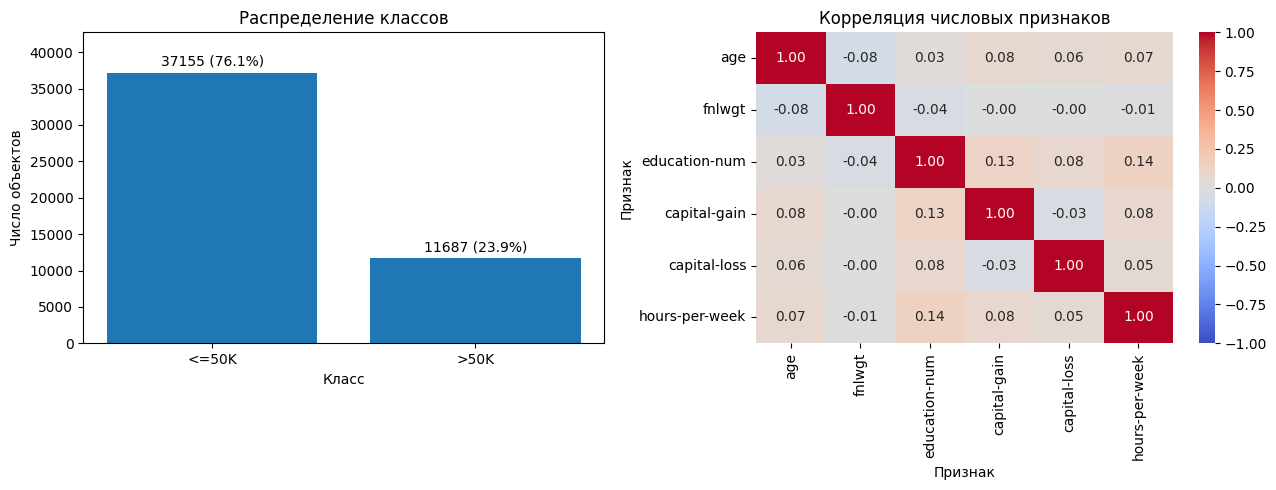

In [5]:
def plot_eda(df: pd.DataFrame, target_col: str) -> matplotlib.figure.Figure:
    """Разведочный анализ датасета.

    Параметры:
        df         — исходный датафрейм, включающий целевую переменную
        target_col — название столбца с целевой переменной

    Возвращает:
        matplotlib.figure.Figure с двумя подграфиками:
        левый — распределение классов, правый — тепловая карта корреляций
    """
    fig, (ax_classes, ax_corr) = plt.subplots(1, 2, figsize=(13, 5))

    target = df[target_col]
    if target_col == "income":
        #Есть метки с точкой
        target = target.str.strip().str.rstrip(".")

    counts = target.value_counts()
    total = counts.sum()
    bars = ax_classes.bar(counts.index.astype(str), counts)
    labels = [f"{count} ({count / total:.1%})" for count in counts]
    ax_classes.bar_label(bars, labels=labels, padding=3)
    ax_classes.margins(y=0.15)
    ax_classes.set(
        title="Распределение классов", xlabel="Класс", ylabel="Число объектов"
    )

    corr = df.drop(columns=target_col).select_dtypes(include="number").corr()
    sns.heatmap(
        corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax_corr
    )
    ax_corr.set(
        title="Корреляция числовых признаков", xlabel="Признак", ylabel="Признак"
    )

    fig.tight_layout()
    return fig



# Загрузка датасета
# TODO: загрузите датасет через fetch_ucirepo(id=UCI_ID)
df: pd.DataFrame = fetch_ucirepo(id=2).data.original

# TODO: вызовите plot_eda и сохраните результат
fig_eda: matplotlib.figure.Figure = plot_eda(df, "income")

# TODO: запишите наблюдения по EDA
eda_comment: str = "Дисбаланс: Класс <=50K составляет 76,1% выборки. Корреляции: Наибольшая по модулю корреляция среди числовых признаков наблюдается между education-num и hours-per-week(0,14)"

### Задание 1.2 — Базовая предобработка (5 баллов)

Создайте датафрейм `df_base`, выполнив **обязательные** шаги предобработки:

1. **Обработка пропусков.** Проверьте наличие явных (`NaN`) и неявных пропусков (например, значения `"unknown"` или `"?"`, нестандартные числовые коды). Заполните или удалите их обоснованно.
2. **Кодирование категориальных признаков.** Все нечисловые столбцы должны быть преобразованы в числовые (например, с помощью `LabelEncoder` или `pd.get_dummies`).

**Требования:**
- В `df_base` не должно остаться `NaN`.
- Все столбцы должны быть числового типа.
- Исходный датафрейм `df` **не перезаписывать**.

> 💡 **Подсказка:** для некоторых датасетов пропуски закодированы не как `NaN`, а как специальные значения — проверьте документацию вашего датасета по ссылке из задания 0.2.

In [6]:
# Базовая предобработка
# TODO: реализуйте обязательные шаги и сохраните результат в df_base

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

df_clean = df.replace("?", np.nan)
missing_counts = df_clean.isna().sum()
print(missing_counts[missing_counts > 0])

income = df_clean["income"].str.strip().str.rstrip(".")
df_clean["income"] = income.map({"<=50K": 0, ">50K": 1})
df_clean = df_clean.drop_duplicates().drop(columns="education")

X: pd.DataFrame = df_clean.drop(columns="income")
y: pd.Series = df_clean["income"]

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE,
)
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.5, stratify=y_holdout,
    random_state=RANDOM_STATE,
)

num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

imputer = ColumnTransformer(
    [
        ("num", SimpleImputer(strategy="mean"), num_cols),
        ("cat", SimpleImputer(strategy="most_frequent"), cat_cols),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test = imputer.transform(X_test)

country_encoder = OneHotEncoder(
    min_frequency=25,
    handle_unknown="infrequent_if_exist",
    sparse_output=False,
)
cat_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

encoder = ColumnTransformer(
    [
        ("country", country_encoder, ["native-country"]),
        ("cat", cat_encoder, cat_cols.drop("native-country")),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train = encoder.fit_transform(X_train)
X_val = encoder.transform(X_val)
X_test = encoder.transform(X_test)

train_df = pd.concat([X_train, y_train], axis=1)
val_df = pd.concat([X_val, y_val], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)

df_base: pd.DataFrame = pd.concat([train_df, val_df, test_df])


workclass         2799
occupation        2809
native-country     857
dtype: int64


### Задание 1.3 — Расширенная предобработка (5 баллов)

На основе `df_base` создайте датафрейм `df_processed`, добавив **дополнительные** шаги по вашему выбору. Возможные варианты:

- Стандартизация числовых признаков (`StandardScaler`).
- Удаление выбросов.
- Удаление сильно скоррелированных признаков (по результатам EDA).
- Удаление дубликатов.

Обоснуйте каждый шаг в переменной `preprocessing_comment`: почему именно эти шаги, и как они должны повлиять на качество модели.

> 💡 **Подсказка:** `df_processed` должен **отличаться** от `df_base` хотя бы одним шагом. Пустое обоснование не засчитывается.

In [7]:
# Расширенная предобработка
# TODO: реализуйте дополнительные шаги и сохраните результат в df_processed

df_processed: pd.DataFrame = df_base.copy()

scaler = StandardScaler()
scaler.fit(train_df[num_cols])
df_processed[num_cols] = scaler.transform(df_processed[num_cols])


# TODO: обоснуйте каждый шаг предобработки
preprocessing_comment: str = """Шаг 1. Заменил знак ? на NaN и посмотрел, сколько пропусков в каждом столбце
Шаг 2. Убрал точки в конце меток income, чтобы одинаковые классы записывались одинаково. Доход <=50K обозначил как 0, >50K как 1
Шаг 3. Удалил полные дубликаты, чтобы одна и та же запись не попала в разные выборки. Убрал столбец education, потому что уровень образования уже указан в education-num
Шаг 4. Разделил данные на train, val и test в пропорции 70/15/15. Использовал стратификацию по income, чтобы доли классов во всех трёх выборках были примерно одинаковыми
Шаг 5. Числовые пропуски заполнил средним по столбцу, категориальные заменил самым частым значением. Средние и моды посчитал на train и использовал для всех трёх выборок
Шаг 6. Сделал one-hot кодирование, чтобы не задавать категориям искусственный порядок. Страны, которые встретились в train меньше 25 раз, объединил в одну группу. Кодировщики обучил на train и применил к val и test. Затем собрал обработанные выборки вместе с income в df_base
Шаг 7. Стандартизировал числовые признаки с помощью StandardScaler, обученного на train. Так числовые признаки стали сопоставимы по масштабу при расчёте расстояний в KNN."""

### Задание 1.4 — Разделение на выборки (5 баллов)

Разделите `df_processed` на три выборки: обучающую, валидационную и тестовую.

**Требования:**
- Пропорция разделения: 60% / 20% / 20% или 70% / 15% / 15% — на ваш выбор.
- Используйте **стратификацию** по целевой переменной (`stratify=y`), чтобы сохранить соотношение классов.
- Зафиксируйте `random_state=RANDOM_STATE`.

Валидационная выборка понадобится в блоке 3 для подбора оптимального порога классификации — **не используйте её для обучения моделей**.

> 💡 **Подсказка:** разделение на три части удобно делать в два вызова `train_test_split`: сначала отделить тест, затем разделить остаток на обучение и валидацию.

In [8]:
# TODO: разделите df_processed на признаки X и целевую переменную y
X: pd.DataFrame = df_processed.drop(columns="income")
y: pd.Series = df_processed["income"]

# TODO: разделите на train / val / test
X_train: pd.DataFrame = X.loc[train_df.index]
X_val: pd.DataFrame = X.loc[val_df.index]
X_test: pd.DataFrame = X.loc[test_df.index]
y_train: pd.Series = y.loc[train_df.index]
y_val: pd.Series = y.loc[val_df.index]
y_test: pd.Series = y.loc[test_df.index]

# Проверка разбивки
if all(v is not None for v in [X_train, X_val, X_test]):
    total = len(X_train) + len(X_val) + len(X_test)
    print(f"Train: {len(X_train)} ({len(X_train)/total:.1%})")
    print(f"Val:   {len(X_val)}   ({len(X_val)/total:.1%})")
    print(f"Test:  {len(X_test)}  ({len(X_test)/total:.1%})")
    print(f"Итого: {total} (исходный: {len(df_processed)})")

Train: 34153 (70.0%)
Val:   7318   (15.0%)
Test:  7319  (15.0%)
Итого: 48790 (исходный: 48790)


---
## Блок 2: Ручная реализация метрик

**Максимум: 30 баллов**

В этом блоке **запрещено** использовать `sklearn.metrics` для вычисления самих метрик. Используйте только `numpy` и `pandas`. После реализации вы сможете проверить себя сравнением с `sklearn`.

### Задание 2.1 — Матрица ошибок, точность, полнота, F1 (10 баллов)

Реализуйте пять функций бинарной классификации, начиная с матрицы ошибок — все остальные метрики выводятся непосредственно из неё.

**Матрица ошибок** возвращает четыре значения:
$$TP, FP, FN, TN$$
где $TP$ — истинно положительные, $FP$ — ложно положительные, $FN$ — ложно отрицательные, $TN$ — истинно отрицательные.

Остальные метрики:

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

$$\text{Precision} = \frac{TP}{TP + FP}, \quad \text{Recall} = \frac{TP}{TP + FN}$$

$$F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

Функции `precision_manual`, `recall_manual`, `f1_manual` должны использовать `confusion_matrix_manual` внутри — не дублировать логику подсчёта TP/FP/FN/TN.

Все функции должны обрабатывать **деление на ноль** — возвращать `0.0` в случае неопределённости.

После реализации проверьте совпадение с `sklearn.metrics` с точностью `1e-6`.

In [9]:
def confusion_matrix_manual(
    y_true: np.ndarray,
    y_pred: np.ndarray
) -> Tuple[int, int, int, int]:
    """Элементы матрицы ошибок для бинарной классификации.

    Параметры:
        y_true — истинные метки классов, массив из 0 и 1
        y_pred — предсказанные метки классов, массив из 0 и 1

    Возвращает:
        Кортеж (TP, FP, FN, TN)
    """
    # TODO: ваш код
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    tp = np.count_nonzero((y_true == 1) & (y_pred == 1))
    fp = np.count_nonzero((y_true == 0) & (y_pred == 1))
    fn = np.count_nonzero((y_true == 1) & (y_pred == 0))
    tn = np.count_nonzero((y_true == 0) & (y_pred == 0))

    return tp, fp, fn, tn


def accuracy_manual(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Доля правильно классифицированных объектов.

    Параметры:
        y_true — истинные метки классов, массив из 0 и 1
        y_pred — предсказанные метки классов, массив из 0 и 1

    Возвращает:
        float — значение accuracy в диапазоне [0, 1]
    """
    # TODO: ваш код — используйте confusion_matrix_manual
    tp, fp, fn, tn = confusion_matrix_manual(y_true, y_pred)
    total = tp + fp + fn + tn
    return (tp + tn) / total if total else 0.0


def precision_manual(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Точность: доля истинно положительных среди предсказанных положительных.

    Параметры:
        y_true — истинные метки классов, массив из 0 и 1
        y_pred — предсказанные метки классов, массив из 0 и 1

    Возвращает:
        float — значение precision в диапазоне [0, 1]; 0.0 при TP + FP = 0
    """
    # TODO: ваш код — используйте confusion_matrix_manual
    tp, fp, _, _ = confusion_matrix_manual(y_true, y_pred)
    predicted_positives = tp + fp
    return tp / predicted_positives if predicted_positives else 0.0


def recall_manual(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Полнота: доля истинно положительных среди всех реальных положительных.

    Параметры:
        y_true — истинные метки классов, массив из 0 и 1
        y_pred — предсказанные метки классов, массив из 0 и 1

    Возвращает:
        float — значение recall в диапазоне [0, 1]; 0.0 при TP + FN = 0
    """
    # TODO: ваш код — используйте confusion_matrix_manual
    tp, _, fn, _ = confusion_matrix_manual(y_true, y_pred)
    actual_positives = tp + fn
    return tp / actual_positives if actual_positives else 0.0


def f1_manual(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """F1-мера: гармоническое среднее точности и полноты.

    Параметры:
        y_true — истинные метки классов, массив из 0 и 1
        y_pred — предсказанные метки классов, массив из 0 и 1

    Возвращает:
        float — значение F1 в диапазоне [0, 1]; 0.0 при P + R = 0
    """
    # TODO: ваш код — используйте confusion_matrix_manual
    tp, fp, fn, _ = confusion_matrix_manual(y_true, y_pred)
    denominator = 2 * tp + fp + fn
    return 2 * tp / denominator if denominator else 0.0


# Проверка реализации относительно sklearn
# (раскомментируйте после реализации функций выше)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
y_demo  = np.array([1, 0, 1, 1, 0, 0, 1, 0])
yp_demo = np.array([1, 0, 0, 1, 0, 1, 1, 0])
print('confusion_matrix_manual:', confusion_matrix_manual(y_demo, yp_demo))
print('sklearn confusion_matrix (TN,FP,FN,TP):', confusion_matrix(y_demo, yp_demo).ravel())
print('Accuracy  — ручная:', accuracy_manual(y_demo, yp_demo),  '| sklearn:', accuracy_score(y_demo, yp_demo))
print('Precision — ручная:', precision_manual(y_demo, yp_demo), '| sklearn:', precision_score(y_demo, yp_demo))
print('Recall    — ручная:', recall_manual(y_demo, yp_demo),    '| sklearn:', recall_score(y_demo, yp_demo))
print('F1        — ручная:', f1_manual(y_demo, yp_demo),        '| sklearn:', f1_score(y_demo, yp_demo))


confusion_matrix_manual: (3, 1, 1, 3)
sklearn confusion_matrix (TN,FP,FN,TP): [3 1 1 3]
Accuracy  — ручная: 0.75 | sklearn: 0.75
Precision — ручная: 0.75 | sklearn: 0.75
Recall    — ручная: 0.75 | sklearn: 0.75
F1        — ручная: 0.75 | sklearn: 0.75


### Задание 2.2 — PR-кривая вручную (8 баллов)

Реализуйте функцию, вычисляющую **PR-кривую** (кривую точность–полнота) путём перебора порогов классификации.

Алгоритм:
1. В качестве порогов используйте все уникальные значения `y_score`, отсортированные по убыванию.
2. Для каждого порога $t$ получите бинарные предсказания: $\hat{y}_i = 1$ если $s_i \geq t$, иначе $0$.
3. Вычислите `precision` и `recall` для каждого порога, используя функции из задания 2.1.

Функция должна возвращать три массива одинаковой длины: `(precision, recall, thresholds)`.

In [10]:
def precision_recall_curve_manual(
    y_true: np.ndarray,
    y_score: np.ndarray
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Вычисление PR-кривой путём перебора порогов.

    Параметры:
        y_true  — истинные метки классов, массив из 0 и 1, размерность (n,)
        y_score — оценки вероятности положительного класса, размерность (n,)

    Возвращает:
        Кортеж (precision, recall, thresholds), каждый — np.ndarray размерности (k,),
        где k — число уникальных порогов
    """
    # TODO: ваш код
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    thresholds = np.unique(y_score)[::-1]

    precision = []
    recall = []

    for threshold in thresholds:
        y_pred = (y_score >= threshold).astype(int)
        precision.append(precision_manual(y_true, y_pred))
        recall.append(recall_manual(y_true, y_pred))

    return np.array(precision), np.array(recall), thresholds

### Задание 2.3 — ROC-кривая и ROC-AUC вручную (8 баллов)

Реализуйте функции для вычисления **ROC-кривой** и площади под ней (AUC).

**ROC-кривая** строится в координатах FPR–TPR при переборе порогов:

$$\text{TPR} = \frac{TP}{TP + FN}, \quad \text{FPR} = \frac{FP}{FP + TN}$$

**AUC** вычисляется численным интегрированием методом трапеций:

$$\text{AUC} = \int_0^1 \text{TPR}(\text{FPR})\, d(\text{FPR}) \approx \sum_{i=1}^{k-1} \frac{\text{TPR}_i + \text{TPR}_{i+1}}{2} \cdot |\text{FPR}_{i+1} - \text{FPR}_i|$$

ROC-кривая должна начинаться в точке (0, 0) и заканчиваться в точке (1, 1).

In [11]:
def roc_curve_manual(
    y_true: np.ndarray,
    y_score: np.ndarray
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Вычисление ROC-кривой путём перебора порогов.

    Параметры:
        y_true  — истинные метки классов, массив из 0 и 1, размерность (n,)
        y_score — оценки вероятности положительного класса, размерность (n,)

    Возвращает:
        Кортеж (fpr, tpr, thresholds), каждый — np.ndarray размерности (k,);
        кривая начинается в (0, 0) и заканчивается в (1, 1)
    """
    # TODO: ваш код
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    thresholds = np.unique(y_score)[::-1]

    fpr = [0.0]
    tpr = [0.0]

    for threshold in thresholds:
        y_pred = (y_score >= threshold).astype(int)
        tp, fp, fn, tn = confusion_matrix_manual(y_true, y_pred)

        negatives = fp + tn
        positives = tp + fn
        fpr.append(fp / negatives if negatives else 0.0)
        tpr.append(tp / positives if positives else 0.0)

    thresholds = np.concatenate(([np.inf], thresholds))
    return np.array(fpr), np.array(tpr), thresholds


def roc_auc_manual(fpr: np.ndarray, tpr: np.ndarray) -> float:
    """Вычисление AUC методом трапеций.

    Параметры:
        fpr — массив значений FPR (ось X ROC-кривой), размерность (k,)
        tpr — массив значений TPR (ось Y ROC-кривой), размерность (k,)

    Возвращает:
        float — площадь под ROC-кривой в диапазоне [0, 1]
    """
    # TODO: ваш код
    fpr = np.asarray(fpr)
    tpr = np.asarray(tpr)

    widths = np.abs(np.diff(fpr))
    heights = (tpr[:-1] + tpr[1:]) / 2
    return float(np.sum(widths * heights))

---
## Блок 3: Классификация

**Максимум: 30 баллов**

Обучите четыре классификатора на `X_train` / `y_train`, оцените их на `X_test` / `y_test`. Для подбора гиперпараметров используйте валидационную выборку `X_val` / `y_val`.

### Задание 3.1 — Бейзлайн: логистическая регрессия (4 балла)

Обучите `LogisticRegression` с параметрами по умолчанию. Задайте явно:
- `random_state=RANDOM_STATE` — для воспроизводимости,
- `max_iter=1000` — чтобы гарантировать сходимость оптимизатора.

Остальные гиперпараметры **не трогайте** — это точка отсчёта для сравнения с остальными моделями.

Сохраните:
- обученную модель в `logreg`,
- вероятности положительного класса на тестовой выборке в `y_score_logreg`.

> 💡 **Подсказка:** `predict_proba` возвращает массив размерности `(n, 2)` — вам нужен второй столбец (индекс `[:, 1]`).

In [12]:
# TODO: обучите логистическую регрессию
logreg: LogisticRegression = LogisticRegression(
    random_state=RANDOM_STATE,
    max_iter=1000,
)
logreg.fit(X_train, y_train)

# TODO: получите вероятности положительного класса на тестовой выборке
y_score_logreg: np.ndarray = logreg.predict_proba(X_test)[:, 1]  # размерность (n_test,)

### Задание 3.2 — Метод k ближайших соседей (7 баллов)

Обучите `KNeighborsClassifier`. Подберите оптимальное значение `k` по **F1-мере на валидационной выборке** в диапазоне нечётных значений от 1 до 21.

Сохраните:
- лучшее значение `k` в `best_k`,
- обученную модель с `best_k` в `knn`,
- вероятности на тестовой выборке в `y_score_knn`.

> 💡 **Подсказка:** метод `predict_proba` у `KNeighborsClassifier` работает только при `algorithm` не `'brute'` для больших датасетов. Если датасет большой — рассмотрите `algorithm='ball_tree'`.

In [13]:
# TODO: подберите оптимальное k по F1 на валидационной выборке
best_k: int = 1
best_f1 = -1.0
# TODO: обучите KNN с best_k
for k in range(1, 22, 2):
    candidate = KNeighborsClassifier(n_neighbors=k)
    candidate.fit(X_train, y_train)
    y_pred_val = candidate.predict(X_val)
    score = f1_manual(y_val, y_pred_val)

    if score > best_f1:
        best_f1 = score
        best_k = k


knn: KNeighborsClassifier = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)

# TODO: получите вероятности на тестовой выборке
y_score_knn: np.ndarray = knn.predict_proba(X_test)[:, 1]  # размерность (n_test,)

### Задание 3.3 — Наивный байесовский классификатор (4 балла)

Обучите `GaussianNB` — вероятностный классификатор, предполагающий независимость признаков и нормальное распределение каждого из них.

Сохраните:
- обученную модель в `gnb`,
- вероятности на тестовой выборке в `y_score_gnb`.

Сравните AUC с логистической регрессией и поразмышляйте: насколько реалистично предположение о независимости признаков для вашего датасета?

In [14]:
# TODO: обучите наивный байесовский классификатор
gnb: GaussianNB = GaussianNB()
gnb.fit(X_train, y_train)
# TODO: получите вероятности на тестовой выборке
y_score_gnb: np.ndarray = gnb.predict_proba(X_test)[:, 1]  # размерность (n_test,)
fpr_logreg, tpr_logreg, _ = roc_curve_manual(y_test, y_score_logreg)
fpr_gnb, tpr_gnb, _ = roc_curve_manual(y_test, y_score_gnb)

auc_logreg = roc_auc_manual(fpr_logreg, tpr_logreg)
auc_gnb = roc_auc_manual(fpr_gnb, tpr_gnb)

print(f"ROC-AUC LogReg = {auc_logreg:.3f}")
print(f"ROC-AUC GaussianNB = {auc_gnb:.3f}")

ROC-AUC LogReg = 0.909
ROC-AUC GaussianNB = 0.864


### Задание 3.4 — Метод опорных векторов (7 баллов)

Обучите `SVC(probability=True)`. Подберите оптимальное значение параметра регуляризации `C` по **F1-мере на валидационной выборке** из сетки `[0.01, 0.1, 1, 10, 100]`.

Сохраните:
- лучшее значение в `best_C`,
- обученную модель с `best_C` в `svm`,
- вероятности на тестовой выборке в `y_score_svm`.

> 💡 **Подсказка:** SVM с ядром RBF и `probability=True` плохо масштабируется — сложность обучения растёт квадратично с числом объектов. На больших датасетах (> 10 000 объектов) время обучения может быть неприемлемым. В таком случае допускается обучать модель на случайной подвыборке обучающих данных — но подумайте, как при этом сохранить соотношение классов. Финальные вероятности `y_score_svm` в любом случае должны вычисляться на полной выборке `X_test`.

In [15]:
X_svm_train, y_svm_train = X_train, y_train
if len(X_train) > 10_000:
    X_svm_train, _, y_svm_train, _ = train_test_split(
        X_train,
        y_train,
        train_size=5_000,
        stratify=y_train,
        random_state=RANDOM_STATE,
    )
# TODO: подберите оптимальное C по F1 на валидационной выборке
best_C: float = 0.01
best_f1_svm = -1.0
for C in [0.01, 0.1, 1, 10, 100]:
    candidate = SVC(C=C)
    candidate.fit(X_svm_train, y_svm_train)
    y_pred_val = candidate.predict(X_val)
    score = f1_manual(y_val, y_pred_val)

    if score > best_f1_svm:
        best_f1_svm = score
        best_C = C

# TODO: обучите SVM с best_C
svm: SVC = SVC(C=best_C, probability=True, random_state=RANDOM_STATE)
svm.fit(X_svm_train, y_svm_train)

# TODO: получите вероятности на тестовой выборке
y_score_svm: np.ndarray = svm.predict_proba(X_test)[:, 1]  # размерность (n_test,)

### Задание 3.5 — Визуализация ROC и PR кривых (4 балла)

Реализуйте функцию `plot_roc_pr`, которая строит **оба графика** на одной фигуре:

- **Левый:** ROC-кривые для всех четырёх моделей на одних осях; пунктирная диагональ (случайный классификатор); AUC каждой модели указан в легенде.
- **Правый:** PR-кривые для всех четырёх моделей; горизонтальная линия на уровне доли положительного класса (случайный классификатор).

Используйте **собственные реализации** `roc_curve_manual` и `precision_recall_curve_manual` из блока 2.

После построения ответьте в `roc_pr_comment`: какая кривая информативнее для вашего датасета и почему?

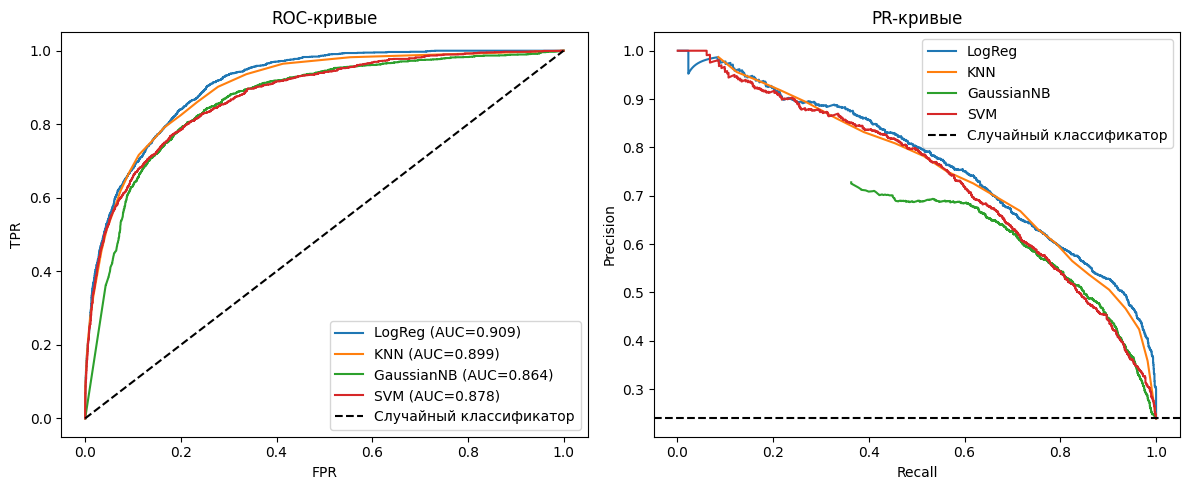

In [16]:
def plot_roc_pr(
    scores_dict: dict,
    y_test: np.ndarray
) -> matplotlib.figure.Figure:
    """Визуализация ROC-кривой и PR-кривой для нескольких моделей.

    Параметры:
        scores_dict — словарь {имя_модели: массив вероятностей на тесте}
        y_test      — истинные метки тестовой выборки

    Возвращает:
        matplotlib.figure.Figure с двумя подграфиками:
        левый — ROC-кривые всех моделей, правый — PR-кривые всех моделей
    """
    # TODO: ваш код
    fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))

    for name, scores in scores_dict.items():
        fpr, tpr, _ = roc_curve_manual(y_test, scores)
        auc_value = roc_auc_manual(fpr, tpr)
        precision, recall, _ = precision_recall_curve_manual(y_test, scores)

        ax_roc.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")
        ax_pr.plot(recall, precision, label=name)

    ax_roc.plot([0, 1], [0, 1], "k--", label="Случайный классификатор")
    ax_pr.axhline(
        np.mean(y_test), color="black", linestyle="--",
        label="Случайный классификатор",
    )

    ax_roc.set(title="ROC-кривые", xlabel="FPR", ylabel="TPR")
    ax_pr.set(title="PR-кривые", xlabel="Recall", ylabel="Precision")
    ax_roc.legend()
    ax_pr.legend()

    fig.tight_layout()
    return fig

scores_dict = {
    "LogReg": y_score_logreg,
    "KNN": y_score_knn,
    "GaussianNB": y_score_gnb,
    "SVM": y_score_svm,
}
# TODO: постройте график после обучения всех четырёх моделей
fig_roc_pr: matplotlib.figure.Figure = plot_roc_pr(scores_dict, y_test)

# TODO: интерпретируйте результаты
roc_pr_comment: str = f"""PR-кривая информативнее, потому что в тестовой выборке Adult только {np.mean(y_test):.1%} записей относятся к классу >50K. По ней видно, какую долю людей с таким доходом модель находит при разных порогах и как часто она права, когда предсказывает этот класс."""  # «PR-кривая информативнее, потому что ..."


### Задание 3.6 — Подбор порога, сводная таблица и матрицы ошибок (8 баллов)

**Часть А. Подбор оптимального порога.**
Для каждой из четырёх моделей подберите оптимальный порог по **F1-мере на валидационной выборке**: переберите пороги от 0.05 до 0.95 с шагом 0.05 и выберите тот, при котором F1 максимально. Сохраните результат в словарь `thresholds`.

**Часть Б. Сводная таблица метрик.**
Реализуйте функцию `compare_models`, которая применяет оптимальные пороги к тестовой выборке и возвращает сводную таблицу метрик.
Таблица должна содержать строки: `LogReg`, `KNN`, `GaussianNB`, `SVM` — и столбцы: `Accuracy`, `Precision`, `Recall`, `F1`, `ROC-AUC`.

**Часть В. Визуализация матриц ошибок.**
Реализуйте функцию `plot_confusion_matrices`, которая строит матрицы ошибок для всех четырёх моделей на одной фигуре (2×2 подграфика). Используйте оптимальные пороги из `thresholds`. Подпишите оси и отобразите значения TP, FP, FN, TN в каждой ячейке.

Используйте **ручную реализацию** `confusion_matrix_manual` из задания 2.1.

> 💡 **Подсказка:** матрица ошибок наглядно показывает, где именно ошибается модель — какой тип ошибок (FP или FN) преобладает. Сравните матрицы моделей: одинаково ли они ошибаются?

,Accuracy,Precision,Recall,F1,ROC-AUC
LogReg,0.843831,0.665399,0.699201,0.681881,0.908713
KNN,0.824156,0.600693,0.791667,0.683083,0.899226
GaussianNB,0.683153,0.425020,0.917237,0.580878,0.863537
SVM,0.841918,0.673672,0.658676,0.666089,0.877677


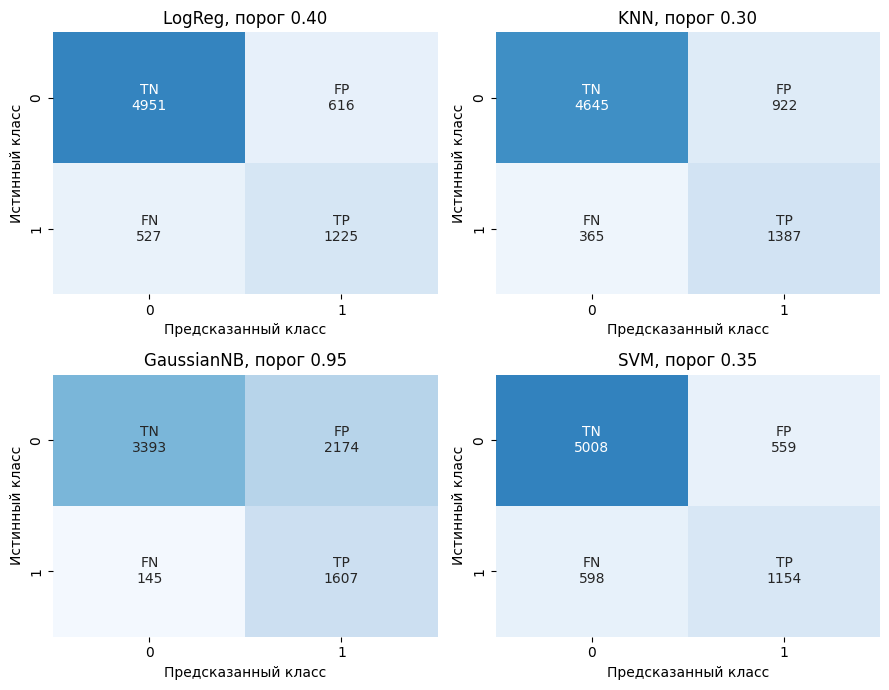

In [17]:
def compare_models(
    models_dict: Dict[str, np.ndarray],
    y_test: np.ndarray,
    thresholds: Dict[str, float]
) -> pd.DataFrame:
    """Сводная таблица метрик классификации для нескольких моделей.

    Параметры:
        models_dict — словарь {имя_модели: массив вероятностей на тесте}
        y_test      — истинные метки тестовой выборки
        thresholds  — словарь {имя_модели: оптимальный_порог}

    Возвращает:
        pd.DataFrame со строками по моделям и столбцами:
        Accuracy, Precision, Recall, F1, ROC-AUC
    """
    # TODO: ваш код
    results = {}

    for name, scores in models_dict.items():
        y_pred = (scores >= thresholds[name]).astype(int)
        fpr, tpr, _ = roc_curve_manual(y_test, scores)

        results[name] = {
            "Accuracy": accuracy_manual(y_test, y_pred),
            "Precision": precision_manual(y_test, y_pred),
            "Recall": recall_manual(y_test, y_pred),
            "F1": f1_manual(y_test, y_pred),
            "ROC-AUC": roc_auc_manual(fpr, tpr),
        }

    return pd.DataFrame.from_dict(results, orient="index")


def plot_confusion_matrices(
    models_dict: Dict[str, np.ndarray],
    y_test: np.ndarray,
    thresholds: Dict[str, float]
) -> matplotlib.figure.Figure:
    """Матрицы ошибок для нескольких моделей на одной фигуре.

    Параметры:
        models_dict — словарь {имя_модели: массив вероятностей на тесте}
        y_test      — истинные метки тестовой выборки
        thresholds  — словарь {имя_модели: оптимальный_порог}

    Возвращает:
        matplotlib.figure.Figure с подграфиками 2×2 — по одному на модель;
        каждый подграфик содержит матрицу ошибок с подписями TP, FP, FN, TN
    """
    # TODO: ваш код — используйте confusion_matrix_manual из задания 2.1
    import seaborn as sns

    fig, axes = plt.subplots(2, 2, figsize=(9, 7))

    for ax, (name, scores) in zip(axes.flat, models_dict.items()):
        threshold = thresholds[name]
        y_pred = (scores >= threshold).astype(int)
        tp, fp, fn, tn = confusion_matrix_manual(y_test, y_pred)

        matrix = [[tn, fp], [fn, tp]]
        labels = [[f"TN\n{tn}", f"FP\n{fp}"], [f"FN\n{fn}", f"TP\n{tp}"]]

        sns.heatmap(
            matrix, annot=labels, fmt="", cmap="Blues", cbar=False,
            vmin=0, vmax=len(y_test), xticklabels=[0, 1], yticklabels=[0, 1],
            ax=ax,
        )
        ax.set(
            title=f"{name}, порог {threshold:.2f}",
            xlabel="Предсказанный класс",
            ylabel="Истинный класс",
        )

    fig.tight_layout()
    return fig

models = {
    "LogReg": logreg,
    "KNN": knn,
    "GaussianNB": gnb,
    "SVM": svm,
}

# Часть А: подбор оптимальных порогов по F1 на валидационной выборке
# TODO: заполните словарь thresholds для каждой модели
thresholds: Dict[str, float] = {}  # {'LogReg': ..., 'KNN': ..., 'GaussianNB': ..., 'SVM': ...}

for name, model in models.items():
    val_scores = model.predict_proba(X_val)[:, 1]
    best_threshold = 0.05
    best_val_f1 = -1.0

    for step in range(5, 100, 5):
        threshold = step / 100
        y_pred_val = (val_scores >= threshold).astype(int)
        score = f1_manual(y_val, y_pred_val)

        if score > best_val_f1:
            best_val_f1 = score
            best_threshold = threshold

    thresholds[name] = best_threshold

# Часть Б: сводная таблица на тестовой выборке
# TODO: вызовите compare_models и сохраните результат
results_df: pd.DataFrame = compare_models(scores_dict, y_test, thresholds)


# Часть В: матрицы ошибок
# TODO: вызовите plot_confusion_matrices и сохраните результат
fig_confusion: matplotlib.figure.Figure = plot_confusion_matrices(
    scores_dict, y_test, thresholds
)

# Отобразите таблицу
if results_df is not None:
    display(results_df.style.highlight_max(axis=0, color='lightgreen'))


---
## Блок 4: Бонусные задания

**Максимум: 20 бонусных баллов**

Бонусные задания выполняются по желанию и не влияют на получение основных баллов.

> ⚠️ **Если вы не планируете выполнять бонусные задания:** удалите объявления функций и классов из этого блока, а переменным присвойте `None` или удалите их полностью. Незаполненные заглушки (`raise NotImplementedError`) вызовут ошибку при запуске тестов.


### ⭐ Задание 4.1 — Работа с дисбалансом классов (10 бонусных баллов)

Исследуйте влияние балансировки классов на качество логистической регрессии.

**Шаг 1.** Визуализируйте распределение классов до и после балансировки с помощью функции `plot_class_distribution`.

**Шаг 2.** Выберите и примените одну из стратегий:
- `SMOTE` из `imblearn.over_sampling` — генерация синтетических примеров миноритарного класса,
- `RandomUnderSampler` из `imblearn.under_sampling` — удаление части примеров мажоритарного класса,
- параметр `class_weight='balanced'` в `LogisticRegression` — взвешивание без изменения выборки.

**Шаг 3.** Обучите `LogisticRegression` на сбалансированных данных и сравните метрики с бейзлайном из задания 3.1. Запишите наблюдения в `balance_comment`: как изменились precision, recall и F1 для миноритарного класса?

> 💡 **Подсказка:** балансировку применяйте **только к обучающей выборке** — `X_train`, `y_train`. Валидационная и тестовая выборки остаются без изменений.

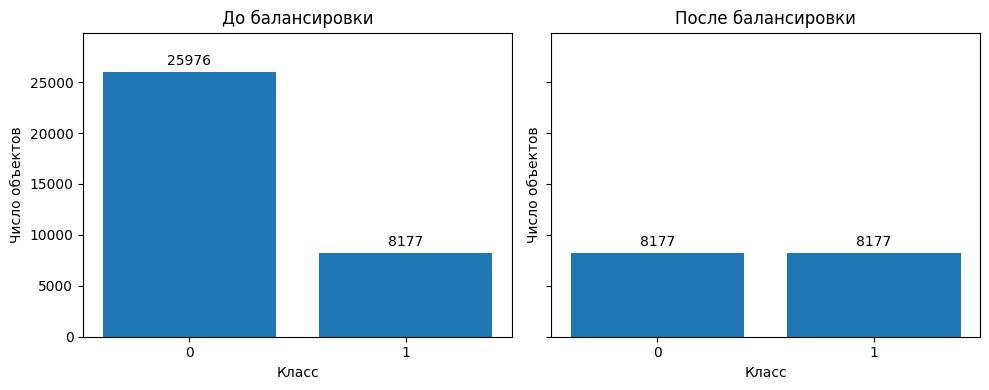

In [18]:
def plot_class_distribution(
    y_before: np.ndarray,
    y_after: np.ndarray
) -> matplotlib.figure.Figure:
    """Визуализация распределения классов до и после балансировки.

    Параметры:
        y_before — целевая переменная до балансировки
        y_after  — целевая переменная после балансировки

    Возвращает:
        matplotlib.figure.Figure с двумя подграфиками (до / после)
    """
    # TODO: ваш код
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

    for ax, y_part, title in zip(
        axes, (y_before, y_after), ("До балансировки", "После балансировки")
    ):
        counts = pd.Series(y_part).value_counts().reindex([0, 1], fill_value=0)
        bars = ax.bar(["0", "1"], counts)
        ax.bar_label(bars, padding=3)
        ax.margins(y=0.15)
        ax.set(title=title, xlabel="Класс", ylabel="Число объектов")

    fig.tight_layout()
    return fig

from imblearn.under_sampling import RandomUnderSampler
sampler = RandomUnderSampler(random_state=RANDOM_STATE)
X_train_balanced, y_train_balanced = sampler.fit_resample(X_train, y_train)

# TODO: примените стратегию балансировки к X_train, y_train
logreg_balanced: LogisticRegression =  LogisticRegression(
    random_state=RANDOM_STATE,
    max_iter=1000,
)
logreg_balanced.fit(X_train_balanced, y_train_balanced)
y_score_logreg_balanced: np.ndarray = logreg_balanced.predict_proba(X_test)[:, 1]  # размерность (n_test,)

# TODO: постройте визуализацию распределения классов
fig_balance: matplotlib.figure.Figure = plot_class_distribution(y_train, y_train_balanced)

y_pred_base = (y_score_logreg >= 0.5).astype(int)
y_pred_balanced = (y_score_logreg_balanced >= 0.5).astype(int)

# TODO: запишите наблюдения
balance_comment: str = (
    "После RandomUnderSampler при пороге 0,5 "
    f"precision изменился с {precision_manual(y_test, y_pred_base):.3f} "
    f"до {precision_manual(y_test, y_pred_balanced):.3f}, "
    f"recall — с {recall_manual(y_test, y_pred_base):.3f} "
    f"до {recall_manual(y_test, y_pred_balanced):.3f}, "
    f"F1 — с {f1_manual(y_test, y_pred_base):.3f} "
    f"до {f1_manual(y_test, y_pred_balanced):.3f}."
)  # «После SMOTE recall вырос с ... до ..., precision упал с ... до ...»

In [19]:
balance_comment

'После RandomUnderSampler при пороге 0,5 precision изменился с 0.742 до 0.569, recall — с 0.618 до 0.838, F1 — с 0.674 до 0.678.'

### ⭐ Задание 4.2 — Логистическая регрессия с нуля (10 бонусных баллов)

Реализуйте класс `LogisticRegressionManual`, обучающий модель методом **полного градиентного спуска** по логарифмической функции потерь с L2-регуляризацией.

На каждой эпохе градиент вычисляется **по всей обучающей выборке** — не по одному объекту (стохастический GD) и не по батчу (мини-батчевый GD).

**Функционал качества** (отрицательное логарифмическое правдоподобие с регуляризацией):

$$Q(\boldsymbol{\theta}, X^\ell) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\mathscr{L}(\boldsymbol{\theta}, \mathbf{x}_i) + \frac{\tau}{2}\|\boldsymbol{\theta}\|^2$$

где функция потерь на одном примере:

$$\mathscr{L}(\boldsymbol{\theta}, \mathbf{x}_i) = y_i \log \sigma(\boldsymbol{\theta}^\top \mathbf{x}_i + \theta_0) + (1 - y_i) \log (1 - \sigma(\boldsymbol{\theta}^\top \mathbf{x}_i + \theta_0))$$

Сигмоида: $\sigma(z) = \dfrac{1}{1 + e^{-z}}$

Градиент по $\boldsymbol{\theta}$ (без смещения $\theta_0$):

$$\nabla_{\boldsymbol{\theta}} Q = \frac{1}{\ell} X^\top (\hat{y} - y) + \tau \boldsymbol{\theta}$$

Шаг обновления параметров:

$$\boldsymbol{\theta} \leftarrow \boldsymbol{\theta} - \eta \cdot \nabla_{\boldsymbol{\theta}} Q$$

где $\eta$ — скорость обучения, $\tau$ — коэффициент регуляризации.

**Требования к классу:**
- Метод `fit` должен обновлять `self.theta` и `self.theta_0` на каждой эпохе и сохранять историю значений $Q$ в `self.loss_history`.
- Метод `predict_proba` должен возвращать массив размерности `(n, 2)` — вероятности обоих классов.
- Функция `plot_loss_curve` должна строить график убывания $Q$ по эпохам.

После обучения сравните ROC-AUC вашей реализации с `sklearn.linear_model.LogisticRegression`.

> ⚠️ **На защите будьте готовы вывести и обосновать приведённые в этом задании формулы.**

ROC-AUC ручной модели = 0.890
ROC-AUC sklearn = 0.909


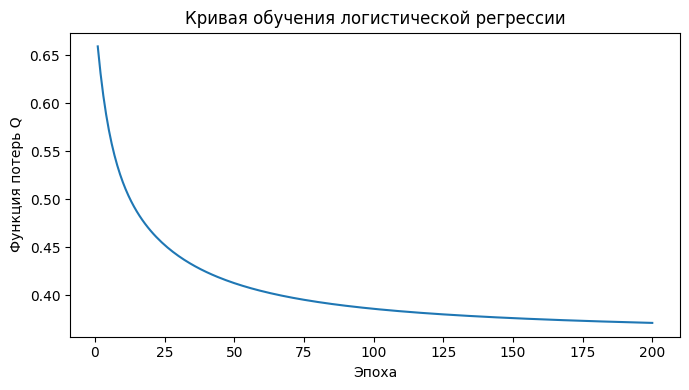

In [20]:
class LogisticRegressionManual:
    """Логистическая регрессия, обучаемая градиентным спуском.

    Атрибуты после обучения:
        theta        — вектор весов, np.ndarray размерности (n_features,)
        theta_0      — смещение (bias), float
        loss_history — значения функционала Q по эпохам, np.ndarray размерности (n_epochs,)
    """

    def __init__(self) -> None:
        self.theta: np.ndarray = None        # размерность (n_features,)
        self.theta_0: float = None
        self.loss_history: np.ndarray = None  # размерность (n_epochs,)

    def fit(
        self,
        X: np.ndarray,
        y: np.ndarray,
        lr: float = 0.01,
        n_epochs: int = 100,
        tau: float = 0.01
    ) -> "LogisticRegressionManual":
        """Обучение модели градиентным спуском.

        Параметры:
            X        — матрица признаков, размерность (ell, n_features)
            y        — вектор меток, размерность (ell,), значения 0 или 1
            lr       — скорость обучения (eta)
            n_epochs — число эпох градиентного спуска
            tau      — коэффициент L2-регуляризации

        Возвращает:
            self
        """
        # TODO: ваш код
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        self.theta = np.zeros(X.shape[1])
        self.theta_0 = 0.0
        self.loss_history = np.zeros(n_epochs)

        for epoch in range(n_epochs):
            probabilities = self.predict_proba(X)[:, 1]
            error = probabilities - y

            grad_theta = (X.T @ error) / len(y) + tau * self.theta
            grad_bias = float(error.mean())
            self.theta -= lr * grad_theta
            self.theta_0 -= lr * grad_bias

            logits = X @ self.theta + self.theta_0
            log_loss = np.mean(np.logaddexp(0, logits) - y * logits)
            penalty = (tau / 2) * np.sum(self.theta ** 2)
            self.loss_history[epoch] = log_loss + penalty

        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        """Предсказание вероятностей классов.

        Параметры:
            X — матрица признаков, размерность (n, n_features)

        Возвращает:
            np.ndarray размерности (n, 2) — вероятности классов 0 и 1;
            сумма по строкам равна 1
        """
        # TODO: ваш код
        X = np.asarray(X, dtype=float)
        logits = X @ self.theta + self.theta_0

        # Сигмоида в численно устойчивой форме.
        p = np.exp(-np.logaddexp(0, -logits))
        return np.column_stack([1 - p, p])


def plot_loss_curve(loss_history: np.ndarray) -> matplotlib.figure.Figure:
    """График убывания функционала Q по эпохам.

    Параметры:
        loss_history — значения Q на каждой эпохе, размерность (n_epochs,)

    Возвращает:
        matplotlib.figure.Figure
    """
    # TODO: ваш код
    fig, ax = plt.subplots(figsize=(7, 4))
    epochs = np.arange(1, len(loss_history) + 1)
    ax.plot(epochs, loss_history)
    ax.set(
        title="Кривая обучения логистической регрессии",
        xlabel="Эпоха",
        ylabel="Функция потерь Q",
    )
    fig.tight_layout()
    return fig

manual_logreg = LogisticRegressionManual()
manual_logreg.fit(X_train, y_train, lr=0.1, n_epochs=200, tau=0.01)

# TODO: обучите LogisticRegressionManual на X_train, y_train
# Убедитесь, что данные стандартизированы — градиентный спуск чувствителен к масштабу
theta: np.ndarray = manual_logreg.theta         # размерность (n_features,)
theta_0: float = manual_logreg.theta_0
loss_history: np.ndarray = manual_logreg.loss_history  # размерность (n_epochs,)

# TODO: постройте кривую обучения
fig_loss: matplotlib.figure.Figure = plot_loss_curve(loss_history)

y_score_logreg_manual = manual_logreg.predict_proba(X_test)[:, 1]
fpr_manual, tpr_manual, _ = roc_curve_manual(y_test, y_score_logreg_manual)
auc_manual = roc_auc_manual(fpr_manual, tpr_manual)

print(f"ROC-AUC ручной модели = {auc_manual:.3f}")
print(f"ROC-AUC sklearn = {auc_logreg:.3f}")

In [22]:
y_score_logreg_manual

array([0.09532517, 0.24898735, 0.34479258, ..., 0.00753869, 0.27619067,
       0.07959262])

---
## Финальные проверки

Перед сдачей убедитесь, что:
- ✅ Все ячейки выполнены (`Kernel → Restart & Run All`)
- ✅ Все обязательные переменные определены и не равны `None`
- ✅ Все графики имеют заголовок и подписи осей
- ✅ Текстовые комментарии (`eda_comment`, `preprocessing_comment`, `roc_pr_comment`) заполнены

In [21]:
required_vars = [
    # Блок 0
    'Student_ID', 'DATASET_NAME', 'UCI_ID', 'TARGET_COL',
    # Блок 1
    'df', 'fig_eda', 'eda_comment',
    'df_base',
    'df_processed', 'preprocessing_comment',
    'X_train', 'X_val', 'X_test', 'y_train', 'y_val', 'y_test',
    # Блок 2
    'confusion_matrix_manual',
    'accuracy_manual', 'precision_manual', 'recall_manual', 'f1_manual',
    'precision_recall_curve_manual',
    'roc_curve_manual', 'roc_auc_manual',
    # Блок 3
    'logreg', 'y_score_logreg',
    'knn', 'y_score_knn', 'best_k',
    'gnb', 'y_score_gnb',
    'svm', 'y_score_svm', 'best_C',
    'fig_roc_pr', 'roc_pr_comment',
    'thresholds', 'compare_models', 'results_df',
    'plot_confusion_matrices', 'fig_confusion',
]

print('=' * 60)
print('ПРОВЕРКА ОБЯЗАТЕЛЬНЫХ ПЕРЕМЕННЫХ:')
print('=' * 60)
all_ok = True
for var in required_vars:
    value = globals().get(var)
    if value is not None:
        print(f'  ✓ {var}')
    else:
        print(f'  ✗ {var} — НЕ ОПРЕДЕЛЕНА!')
        all_ok = False

bonus_vars = [
    # Блок 4 (бонус)
    'logreg_balanced', 'y_score_logreg_balanced',
    'fig_balance', 'balance_comment',
    'LogisticRegressionManual', 'theta', 'theta_0',
    'loss_history', 'fig_loss',
]

print()
print('=' * 60)
print('ПРОВЕРКА БОНУСНЫХ ПЕРЕМЕННЫХ:')
print('=' * 60)
for var in bonus_vars:
    value = globals().get(var)
    if value is not None:
        print(f'  ✓ {var}')
    else:
        print(f'  ○ {var} — не выполнено (бонус)')

print()
if all_ok:
    print('✅ Все обязательные переменные определены. Работа готова к сдаче!')
else:
    print('⚠️  Есть незаполненные обязательные переменные. Проверьте код.')


ПРОВЕРКА ОБЯЗАТЕЛЬНЫХ ПЕРЕМЕННЫХ:
  ✓ Student_ID
  ✓ DATASET_NAME
  ✓ UCI_ID
  ✓ TARGET_COL
  ✓ df
  ✓ fig_eda
  ✓ eda_comment
  ✓ df_base
  ✓ df_processed
  ✓ preprocessing_comment
  ✓ X_train
  ✓ X_val
  ✓ X_test
  ✓ y_train
  ✓ y_val
  ✓ y_test
  ✓ confusion_matrix_manual
  ✓ accuracy_manual
  ✓ precision_manual
  ✓ recall_manual
  ✓ f1_manual
  ✓ precision_recall_curve_manual
  ✓ roc_curve_manual
  ✓ roc_auc_manual
  ✓ logreg
  ✓ y_score_logreg
  ✓ knn
  ✓ y_score_knn
  ✓ best_k
  ✓ gnb
  ✓ y_score_gnb
  ✓ svm
  ✓ y_score_svm
  ✓ best_C
  ✓ fig_roc_pr
  ✓ roc_pr_comment
  ✓ thresholds
  ✓ compare_models
  ✓ results_df
  ✓ plot_confusion_matrices
  ✓ fig_confusion

ПРОВЕРКА БОНУСНЫХ ПЕРЕМЕННЫХ:
  ✓ logreg_balanced
  ✓ y_score_logreg_balanced
  ✓ fig_balance
  ✓ balance_comment
  ✓ LogisticRegressionManual
  ✓ theta
  ✓ theta_0
  ✓ loss_history
  ✓ fig_loss

✅ Все обязательные переменные определены. Работа готова к сдаче!
